# Project 1 – Detecting Moving Objects in DAS Recordings

Ceyda (ER2347), Sema Sert (ER2337)

# 1. Introduction



## 1.1 What is DAS?

Distributed Acoustic Sensing (DAS) uses a fiber optic cable as a vibration sensor. Laser pulses are sent through the cable, and the backscattered light is used to measure the strain rate at many points along the cable. Passing vehicles make the cable vibrate, so DAS can be used to monitor traffic.



### 1.2 From Data to Image

The measurements form a 2D matrix: one dimension is time and the other is the position on the cable. We treat this matrix as an image. Moving vehicles appear as **slanted lines**, and the slope of a line gives the speed of the vehicle.



### 1.3 Project Objective

We analyze real DAS data from Jana Pawła II Street. Our goals are to:

1. reduce the noise,
2. enhance the slanted lines,
3. detect the lines automatically,
4. calculate the speed (km/h) and the direction of each vehicle.



### 1.4 Data and Segments

We use the real recordings from 7 May 2024. They have no ground truth (no information about the real vehicles), so we check our results visually. We analyze three continuous 2-minute segments: two assigned to us (A: Sema, B: Ceyda) and one chosen by us (C), as required for teams of two. The same processing is applied to all three segments.

# 2. Data Loading



## 2.1 Constants and Data Folders

In this section we load the real DAS data. First, we import the libraries and define the constants given in the project description (dx, dt, file duration, number of samples per file) and the data folders.

In [107]:
import os
import glob
import datetime

import numpy as np
import matplotlib.pyplot as plt

# Information from the project description
DX = 5.106500953873407     # distance between two channels [m]
DT = 0.0016                # time between two samples [s]
FS = 1 / DT                # sampling frequency [Hz] (625 Hz)
FILE_SECONDS = 10          # length of one file [s]
SAMPLES_PER_FILE = 6250    # number of time samples in one file
FILES_PER_SEGMENT = 12     # 12 files x 10 s = 2 minutes
DATE = "2024-05-07"

# Folders with the data
folders = ["vision", "ceyda's dataset", "sema's dataset", "other dataset"]

### 2.2 Finding the Files and Continuous Blocks

We find all data files in the folders and check which files follow each other without a gap. The files are not continuous, so a 2-minute segment can only be taken from files that are exactly 10 s apart. We also use the full dataset (vision) to see where the gaps are and, later, to choose segment C.


In [108]:
def find_files(folders):
    """Find all .npy files in the folders. Returns a dict {'HHMMSS': path}."""
    files = {}
    for folder in folders:
        for path in glob.glob(os.path.join(folder, "*.npy")):
            name = os.path.basename(path)[:6]
            files[name] = path
    return dict(sorted(files.items()))

def get_time(name):
    """Change a file name like '093752' into a date and time."""
    return datetime.datetime.strptime(f"{DATE} {name}", "%Y-%m-%d %H%M%S")

def find_blocks(names):
    """Put the file names into blocks. Files in one block are exactly 10 s apart."""
    blocks = []
    block = [names[0]]
    for i in range(1, len(names)):
        gap = (get_time(names[i]) - get_time(names[i - 1])).total_seconds()
        if gap == FILE_SECONDS:
            block.append(names[i])
        else:
            blocks.append(block)
            block = [names[i]]
    blocks.append(block)
    return blocks


In [109]:
files = find_files(folders)
print(f"Number of files found: {len(files)}")
print(f"First file: {next(iter(files))}, last file: {list(files)[-1]}")
print("\nContinuous blocks:")
for block in find_blocks(list(files)):
    print(f"  {block[0]} -> {block[-1]}: {len(block):3d} files = {len(block) * FILE_SECONDS / 60:.1f} min")

Number of files found: 259
First file: 090017, last file: 094332

Continuous blocks:
  090017 -> 090227:  14 files = 2.3 min
  090252 -> 094332: 245 files = 40.8 min


We found 259 different files, the same number as in the project description. 

They form two continuous blocks: 14 files (2.3 min) starting at 09:00:17 and 245 files (40.8 min) starting at 09:02:52. Between the blocks, 15 seconds of data are missing. A 2-minute segment must be inside one block.


### 2.3 Loading the Three Segments

We load the three segments A, B and C: for each segment, its 12 files are put one under the other along the time axis. If a file is missing, the code stops with an error.


In [110]:
def load_segment(start_name):

    start = get_time(start_name)
    names = []
    for k in range(FILES_PER_SEGMENT):
        t = start + datetime.timedelta(seconds=k * FILE_SECONDS)
        names.append(t.strftime("%H%M%S"))

    missing = [n for n in names if n not in files]
    if missing:
        raise FileNotFoundError(f"Segment is not continuous, missing files: {missing}")

    parts = []
    for n in names:
        part = np.load(files[n])
        assert part.shape[0] == SAMPLES_PER_FILE, f"{n}: wrong number of samples"
        parts.append(part)
    return np.concatenate(parts, axis=0), start


Start times of the three segments.

In [111]:
segments = {"A": "093752", "B": "093822", "C": "091202"}

data = {}          # the data of each segment
start_time = {}    # the start time of each segment
for label, start in segments.items():
    data[label], start_time[label] = load_segment(start)
    end = start_time[label] + datetime.timedelta(seconds=data[label].shape[0] * DT)
    print(f"{label}  {start_time[label].time()} -> {end.time()}  shape={data[label].shape}  dtype={data[label].dtype}")

n_channels = data["A"].shape[1]
print(f"\nNumber of channels: {n_channels} -> monitored length = {n_channels * DX:.1f} m")

A  09:37:52 -> 09:39:52  shape=(75000, 52)  dtype=float32
B  09:38:22 -> 09:40:22  shape=(75000, 52)  dtype=float32
C  09:12:02 -> 09:14:02  shape=(75000, 52)  dtype=float32

Number of channels: 52 -> monitored length = 265.5 m


All 36 files were found, so the three segments are continuous. Each segment is a matrix of 75000 × 52 values: 75000 time samples (12 files × 10 s = 120 s) and 52 channels. The 52 channels cover a monitored length of 265.5 m.

### 2.4 Selected Segments

The project description says that the chosen segment must not overlap the assigned segments. Here we check this. We also measure how much A and B overlap.

In [112]:
SEGMENT_SECONDS = FILES_PER_SEGMENT * FILE_SECONDS     # 120 s

def start_gap(name1, name2):
    """Time between the start of two segments [s]."""
    return abs((get_time(name1) - get_time(name2)).total_seconds())

for label in ["A", "B"]:
    print(f"C overlaps {label}: {start_gap(segments['C'], segments[label]) < SEGMENT_SECONDS}")
print(f"A and B overlap by {SEGMENT_SECONDS - start_gap(segments['A'], segments['B']):.0f} s")


C overlaps A: False
C overlaps B: False
A and B overlap by 90 s


Segment C does not overlap A or B. Segments A and B overlap by 90 seconds, because they were assigned this way.


### 2.5 Why Did We Choose Segment C?

We wanted a segment with a lot of traffic, so that our method is tested on many vehicles. To check how active segment C is, we calculate the standard deviation (it measures how strong the vibrations are) of every possible 2-minute window in the full dataset (12 files in a row with no gaps).

In [113]:
# Step 1: Find std of every file in the dataset
file_names = list(files)
file_std = {}
for name in file_names:
    file_std[name] = np.load(files[name]).std()

In [114]:
# Step 2: std of every 2-minute window (12 files in a row)
window_starts = []
window_std = []
for block in find_blocks(file_names):
    for k in range(len(block) - FILES_PER_SEGMENT + 1):
        names = block[k:k + FILES_PER_SEGMENT]
        variance = np.mean([file_std[n] ** 2 for n in names])
        window_starts.append(names[0])
        window_std.append(np.sqrt(variance))
window_std = np.array(window_std)

In [115]:
# Step 3: find the windows that do not overlap A or B
free = np.array([start_gap(s, segments["A"]) >= SEGMENT_SECONDS and
                 start_gap(s, segments["B"]) >= SEGMENT_SECONDS for s in window_starts])


In [116]:
# Step 4: show the best windows and the rank of C
print(f"All windows: {len(window_starts)}, windows not overlapping A or B: {free.sum()}")
print("Top 8 windows (start time, std):")
count = 0
for i in np.argsort(-window_std):      # best windows first
    if free[i] and count < 8:
        print(f"  {window_starts[i]}  {window_std[i]:.3e}")
        count += 1

c_std = window_std[window_starts.index(segments["C"])]
rank = (window_std[free] > c_std).sum() + 1
print(f"\nStd of C: {c_std:.3e}")
print(f"Median std of all windows: {np.median(window_std):.3e}")
print(f"Rank of C: {rank} of {free.sum()}")

All windows: 237, windows not overlapping A or B: 211
Top 8 windows (start time, std):
  091652  7.927e-07
  091702  7.927e-07
  091642  7.926e-07
  091632  7.901e-07
  091712  7.460e-07
  091202  7.117e-07
  091152  7.003e-07
  091142  7.000e-07

Std of C: 7.117e-07
Median std of all windows: 4.626e-07
Rank of C: 6 of 211


**Result:**

- Segment C has std = 7.1e-7. The median of all windows is 4.6e-7, so C is about 1.5 times more active than a typical window.
- C is 6th of the 211 windows that do not overlap A or B (top 3%).
- The five windows above C start between 09:16:32 and 09:17:12, only 10 s apart, so they cover almost the same time: one busy period around 09:16–09:19. Their std is at most 7.9e-7, about 10% higher than C. C is the most active window outside this period, so it is one of the most active segments of the recording.



# 3. Exploratory Data Analysis (EDA)

In this section, we take a first look at the data from the three selected segments. We calculate some basic statistics, check how the values are distributed, and look at how the signal changes over time and between channels.

The main goal is to understand our data better before applying any filtering or image processing methods.

### 3.1 Descriptive Statistics

We calculate basic statistics of the raw values for each segment: mean, standard deviation, minimum, maximum and percentiles.


In [117]:
def get_stats(x):
    p = np.percentile(x, [1, 5, 25, 50, 75, 95, 99])
    return [x.mean(), x.std(), x.min(), x.max()] + list(p)

stat_names = ["mean", "std", "min", "max", "1%", "5%", "25%", "median", "75%", "95%", "99%"]
all_stats = [get_stats(x) for x in data.values()]

print(f"{'':8s}{'A':>13s}{'B':>13s}{'C':>13s}")
for i, name in enumerate(stat_names):
    line = f"{name:8s}"
    for s in all_stats:
        line += f"{s[i]:13.3e}"
    print(line)

                    A            B            C
mean        4.508e-11    2.171e-11    8.758e-11
std         4.937e-07    5.595e-07    7.117e-07
min        -6.515e-05   -6.515e-05   -4.235e-05
max         6.981e-05    6.981e-05    4.132e-05
1%         -1.226e-06   -1.439e-06   -1.880e-06
5%         -4.086e-07   -4.813e-07   -6.568e-07
25%        -9.024e-08   -9.526e-08   -1.228e-07
median      0.000e+00    0.000e+00    0.000e+00
75%         8.774e-08    9.275e-08    1.203e-07
95%         4.061e-07    4.788e-07    6.568e-07
99%         1.246e-06    1.466e-06    1.898e-06


The values are very small, so the data must be rescaled before image processing. 

The mean is almost zero and the percentiles are symmetric, so the signal goes up and down around zero. The minimum and maximum are 20–55 times larger than the 1% and 99% percentiles, so a few values are very large. Because of this, we use robust measures (median, percentiles) in the next steps.



### 3.2 Histogram

The histogram shows how the raw values of the three segments are distributed.


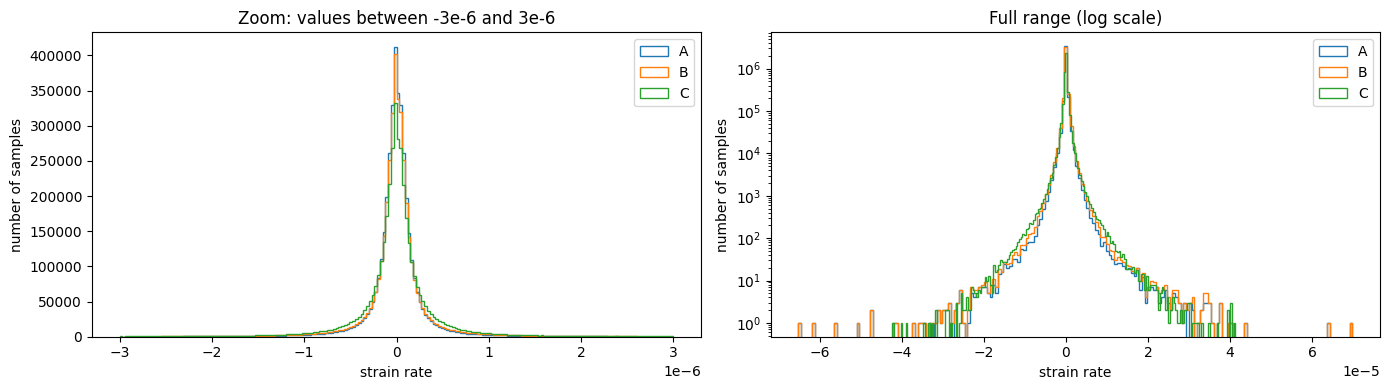

In [118]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for label, x in data.items():
    values = x.flatten()
    axes[0].hist(values, bins=200, range=(-3e-6, 3e-6), histtype="step", label=label)
    axes[1].hist(values, bins=200, histtype="step", label=label)
axes[0].set_title("Zoom: values between -3e-6 and 3e-6")
axes[1].set_title("Full range (log scale)")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("strain rate")
    ax.set_ylabel("number of samples")
    ax.legend()
plt.tight_layout()
plt.show()

The left plot is zoomed in to the center (values between −3 × 10⁻⁶ and 3 × 10⁻⁶). The right plot shows the full range with a log scale, so the rare large values are also visible.

Most values are very close to zero: the histogram has a narrow peak at zero and is symmetric. The log-scale plot shows long tails: a few values reach about ±4–7 × 10⁻⁵, but each bin there contains only a few samples. 

The peak of segment C is lower and wider than the peaks of A and B, so the values of C are more spread out.


### 3.3 Variation Across Space and Time

First, we look at each segment as a time–space image (absolute value after removing the mean of each channel).


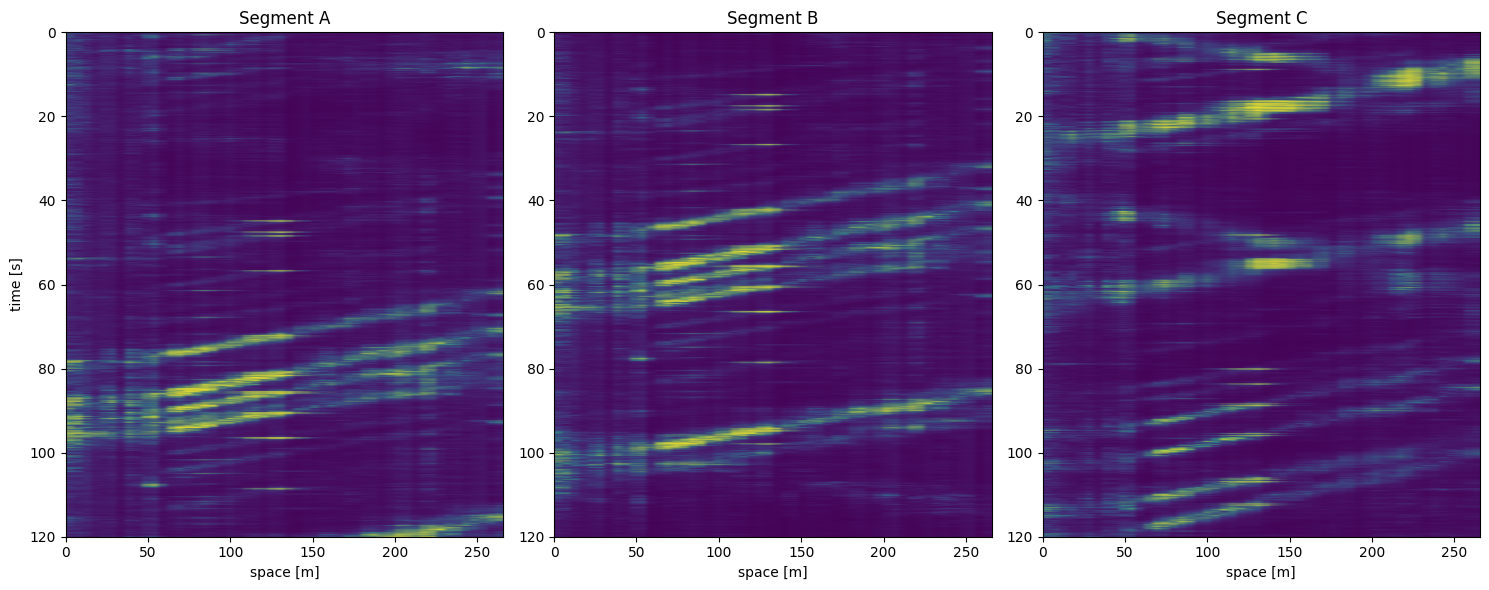

In [119]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, (label, x) in zip(axes, data.items()):
    img = np.abs(x - x.mean(axis=0))
    ax.imshow(img, aspect="auto", vmax=np.percentile(img, 99), extent=[0, n_channels * DX, 120, 0])
    ax.set_title(f"Segment {label}")
    ax.set_xlabel("space [m]")
axes[0].set_ylabel("time [s]")
plt.tight_layout()
plt.show()


The moving vehicles are visible as slanted lines. 

In segments A and B, all lines go in the same direction; in segment C, there are lines in both directions. 

Some lines are thick and bright, others are thin and faint. There are also thin horizontal lines (all channels at the same time) and vertical stripes, especially between 0 and 50 m. The same vehicles appear in A (around 75–95 s) and B (around 45–65 s), because the two segments overlap.



Next, we measure the variability with the standard deviation: for each channel (space) and for each 1-second block (time).


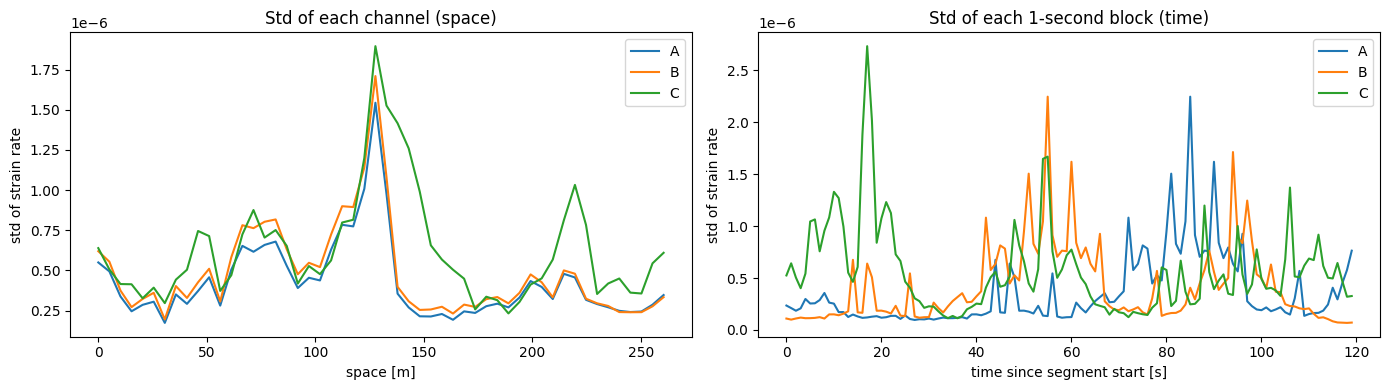

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# std of each channel (space)
positions = np.arange(n_channels) * DX
for label, x in data.items():
    axes[0].plot(positions, x.std(axis=0), label=label)
axes[0].set_title("Std of each channel (space)")
axes[0].set_xlabel("space [m]")
axes[0].set_ylabel("std of strain rate")
axes[0].legend()

# std of each 1-second block (time)
sec = round(1 / DT)    # 625 samples = 1 second
for label, x in data.items():
    n_sec = x.shape[0] // sec
    blocks = x[:n_sec * sec].reshape(n_sec, sec, -1)
    axes[1].plot(blocks.std(axis=(1, 2)), label=label)
axes[1].set_title("Std of each 1-second block (time)")
axes[1].set_xlabel("time since segment start [s]")
axes[1].set_ylabel("std of strain rate")
axes[1].legend()

plt.tight_layout()
plt.show()

The left plot shows the standard deviation of each channel. It tells us which positions on the cable are more active. 

The right plot shows the standard deviation in 1-second blocks. It tells us when the signal is strong.

In all three segments, the strongest channel is at about 128 m, and some channels (for example at about 31 m) are much weaker. In time, the standard deviation is low most of the time, with short peaks that match the bright slanted lines in the images above. The highest peak of A (at 85 s) and of B (at 55 s) is the same moment (09:39:17). Segment C is more active than A and B, even in its quiet moments.


### 3.4 Summary

What we learned from the EDA:

- The values are very small (about 10⁻⁷) → the data must be rescaled.
- A few values are very large compared with the rest → we use robust measures (median, percentiles).
- The channels have very different strength (strongest at about 128 m) → each channel is normalized.
- Thin horizontal lines appear in all channels at the same time → this common noise is removed.

# 4. Frequency Analysis

In this section, we look at the frequencies in the signal. We apply the FFT to each channel separately. We also use the STFT to see how the frequencies change in time.

The sampling frequency is 625 Hz, so the highest frequency we can see is 312.5 Hz.

The goal is to choose the frequency band for our filter.



### 4.1 FFT of Each Channel

We calculate the FFT of each channel and then take the mean of all channels. The plot shows the mean spectrum of segments A, B and C.

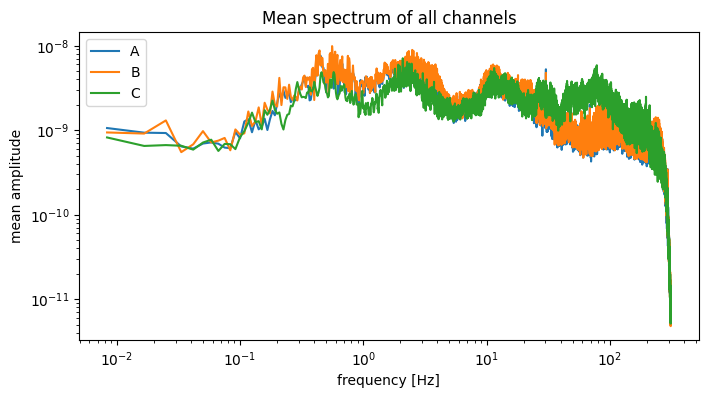

In [121]:
# FFT of every channel (along the time axis)
freqs = np.fft.rfftfreq(data["A"].shape[0], DT)     # frequency of each FFT value [Hz]

plt.figure(figsize=(8, 4))
for label, x in data.items():
    spectrum = np.abs(np.fft.rfft(x, axis=0)) / x.shape[0]    # shape: (frequency, channel)
    plt.loglog(freqs[1:], spectrum.mean(axis=1)[1:], label=label)   # mean of all channels
plt.xlabel("frequency [Hz]")
plt.ylabel("mean amplitude")
plt.title("Mean spectrum of all channels")
plt.legend()
plt.show()

**What we see:**

- The three segments have a similar shape.
- There are peaks near 1-3 Hz, near 10 Hz and near 100 Hz.
- The signal drops fast near 300 Hz. This is because the highest frequency we can see is 312.5 Hz.
- Segment C has more energy between 50 and 100 Hz than A and B.

### 4.2 Frequency and Channel Map

This map shows the FFT of every channel in segment C. The x-axis is the position on the cable and the y-axis is the frequency.

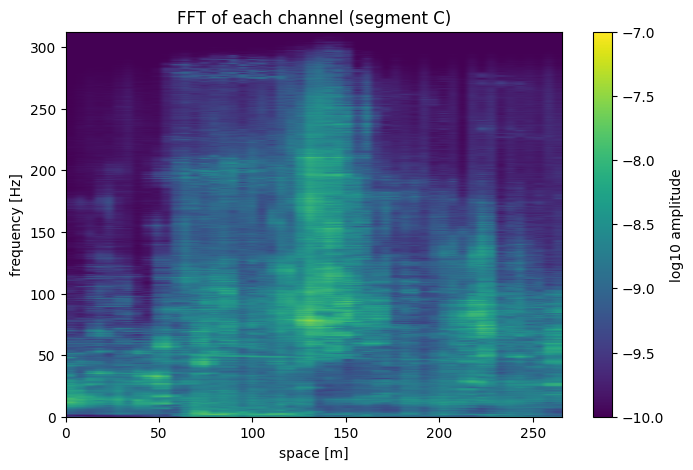

In [122]:
# Frequency x channel map of segment C
spectrum = np.abs(np.fft.rfft(data["C"], axis=0)) / data["C"].shape[0]

plt.figure(figsize=(8, 5))
plt.imshow(np.log10(spectrum + 1e-20), aspect="auto", origin="lower",
           extent=[0, n_channels * DX, 0, freqs[-1]], vmin=-10, vmax=-7)
plt.colorbar(label="log10 amplitude")
plt.xlabel("space [m]")
plt.ylabel("frequency [Hz]")
plt.title("FFT of each channel (segment C)")
plt.show()

**What we see:**

- The signal is strongest around 125-150 m. This is the same place as the peak in Section 3.3.
- Most of the energy is below 250 Hz.
- The first channels, from 0 to 50 m, are weaker.

### 4.3 Spectrogram

The spectrogram is made with the STFT. It shows how the frequencies change in time. We use the most active channel. The code finds it automatically with the std.

Channel: 25 -> position 128 m


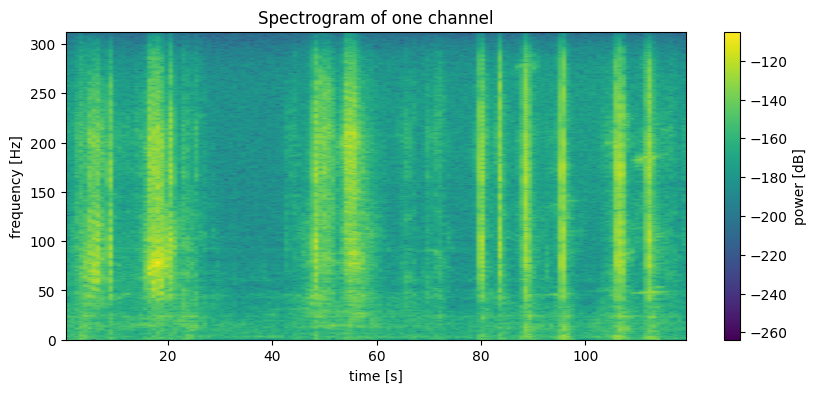

In [123]:
# Spectrogram (STFT) of the most active channel in segment C
best_channel = data["C"].std(axis=0).argmax()
print("Channel:", best_channel, "-> position", round(best_channel * DX), "m")

plt.figure(figsize=(10, 4))
plt.specgram(data["C"][:, best_channel], NFFT=1024, Fs=FS, noverlap=512)
plt.xlabel("time [s]")
plt.ylabel("frequency [Hz]")
plt.title("Spectrogram of one channel")
plt.colorbar(label="power [dB]")
plt.show()

**What we see:**

- The vertical stripes are vehicles passing the channel.
- When a vehicle passes, many frequencies get strong at the same time up to about 250 Hz.
- Between the vehicles the signal is weak.

### 4.4 Which Band Shows the Moving Objects?

Now we keep only one frequency band at a time and plot the first 40 seconds of segment C. The slanted lines are the moving vehicles.

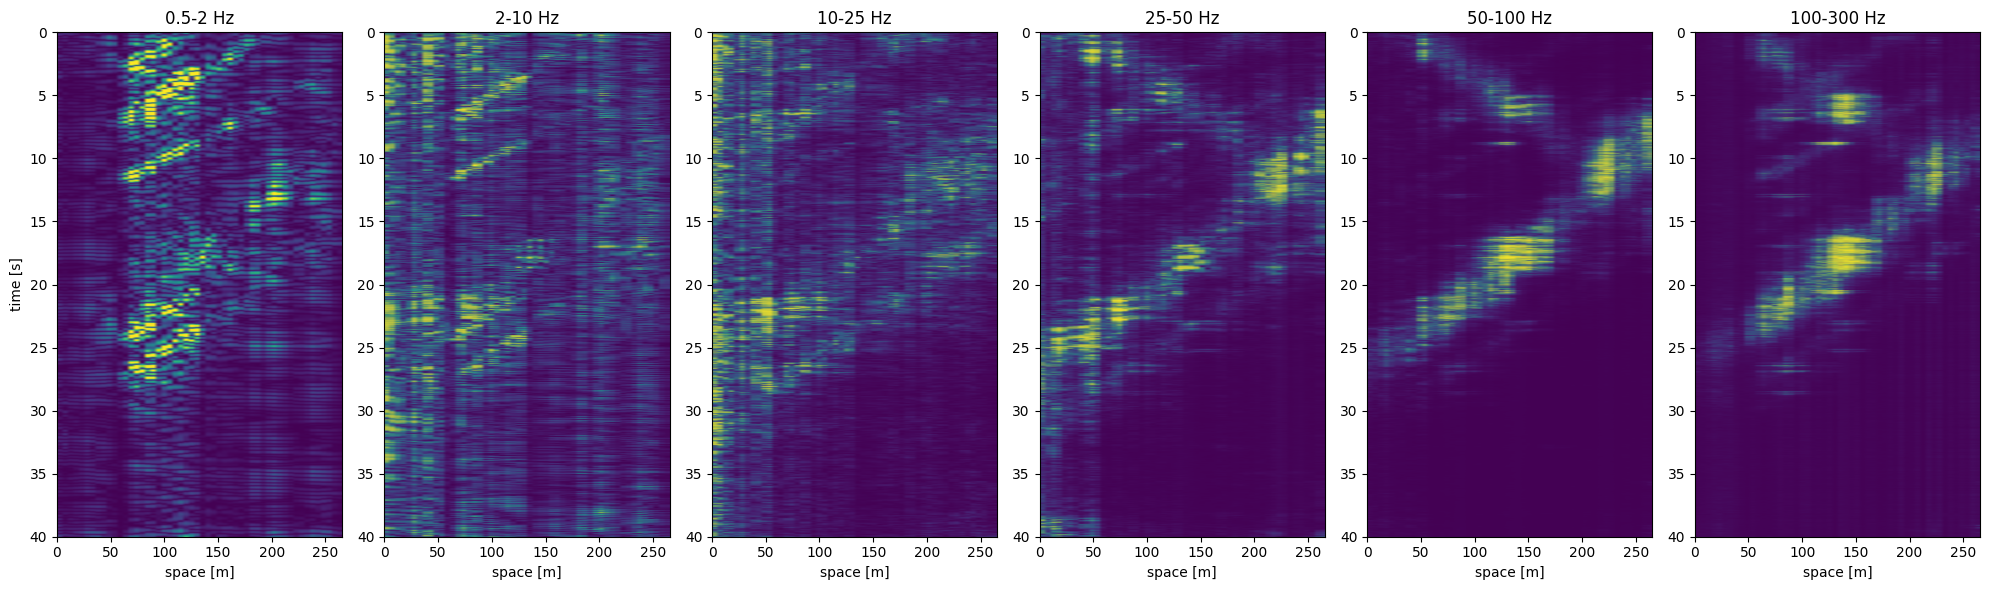

In [124]:
# Which frequency band shows the moving objects?
# We keep only one band at a time (FFT filter) and look at the first 40 seconds of segment C.
def band_filter(x, low, high):
    spec = np.fft.rfft(x, axis=0)
    f = np.fft.rfftfreq(x.shape[0], DT)
    spec[(f < low) | (f > high)] = 0          # remove everything outside the band
    return np.fft.irfft(spec, n=x.shape[0], axis=0)

x = data["C"][:25000]                          # 25000 samples = 40 seconds
bands = [(0.5, 2), (2, 10), (10, 25), (25, 50), (50, 100), (100, 300)]

fig, axes = plt.subplots(1, 6, figsize=(20, 6))
for ax, (low, high) in zip(axes, bands):
    y = np.abs(band_filter(x, low, high))
    ax.imshow(y, aspect="auto", vmin=0, vmax=np.percentile(y, 99),
              extent=[0, n_channels * DX, 40, 0])
    ax.set_title(f"{low}-{high} Hz")
    ax.set_xlabel("space [m]")
axes[0].set_ylabel("time [s]")
plt.tight_layout()
plt.show()

**What we see:**

- **Below 25 Hz:** There are many vertical stripes. This is noise in all channels at the same time. The lines are hard to see.
- **25-100 Hz:** The slanted lines are clear. We can see both thick and thin lines.
- **100-300 Hz:** The lines are also visible, but they look more blurry.

**Decision:** We start with a band-pass filter of **25-100 Hz**. We will test other values in Section 6.

Because we remove everything above 100 Hz, we can also downsample the data later to about 208 Hz.

## 5. Flowchart of the Algorithm

The flowchart shows the main steps of our algorithm. If we change something later, we will update it.

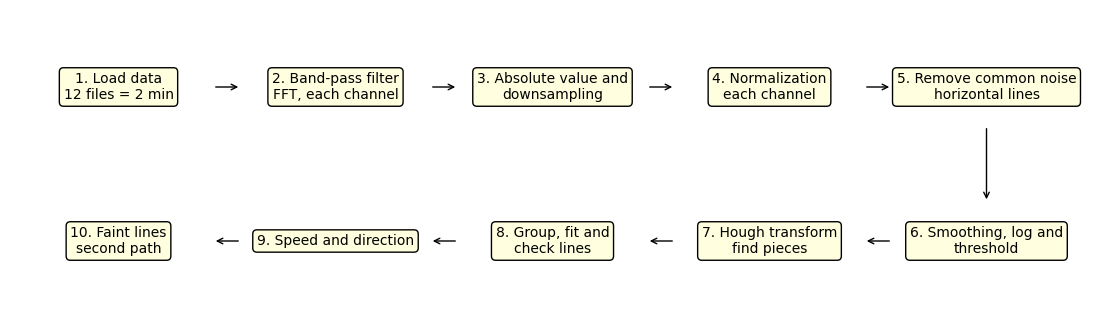

In [125]:
# Flowchart of the algorithm
steps = ["1. Load data\n12 files = 2 min",
         "2. Band-pass filter\nFFT, each channel",
         "3. Absolute value and\ndownsampling",
         "4. Normalization\neach channel",
         "5. Remove common noise\nhorizontal lines",
         "6. Smoothing, log and\nthreshold",
         "7. Hough transform\nfind pieces",
         "8. Group, fit and\ncheck lines",
         "9. Speed and direction",
         "10. Faint lines\nsecond path"]

# Position of each box: first row goes left to right, second row goes right to left
positions = [(0.5, 1.5), (1.5, 1.5), (2.5, 1.5), (3.5, 1.5), (4.5, 1.5),
             (4.5, 0.5), (3.5, 0.5), (2.5, 0.5), (1.5, 0.5), (0.5, 0.5)]

fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(0, 5)
ax.set_ylim(0, 2)
ax.axis("off")
for i in range(len(steps)):
    x, y = positions[i]
    ax.text(x, y, steps[i], ha="center", va="center", fontsize=10,
            bbox=dict(boxstyle="round", facecolor="lightyellow", edgecolor="black"))
    if i < len(steps) - 1:      # arrow to the next box
        x2, y2 = positions[i + 1]
        shrink = 70 if y == y2 else 30
        ax.annotate("", xy=(x2, y2), xytext=(x, y),
                    arrowprops=dict(arrowstyle="->", shrinkA=shrink, shrinkB=shrink))
plt.show()

| Step | What it does | Why |
|---|---|---|
| 1. Load data | Puts 12 files together to make 2 minutes | We get one 2D image with time and space |
| 2. Band-pass filter | Keeps only 25 to 100 Hz with the FFT, for each channel | Removes slow changes and high frequency noise |
| 3. Absolute value and downsampling | Takes the absolute value and the mean of 125 samples | Smaller data and faster code. The new time step is 0.2 s |
| 4. Normalization | Divides each channel by its median | All channels get a similar level |
| 5. Remove common noise | Subtracts the median of all channels at each time | Removes horizontal lines. They are noise at the same time in all channels |
| 6. Smoothing, log and threshold | Gaussian filter, log, Otsu threshold and removing small parts | We get a clean binary mask |
| 7. Hough transform | Finds straight pieces in the mask | Each vehicle is a slanted line |
| 8. Group, fit and check lines | Joins the pieces, fits the line again and removes bad lines | One good line for each vehicle |
| 9. Speed and direction | distance = channels x DX, time = rows x 0.2 s, speed = distance / time x 3.6 km/h | The slope of the line gives the speed and the sign gives the direction |
| 10. Faint lines | Removes the strong lines and repeats steps 6 to 8 | Finds the faint lines of the cars |

Steps 1 to 9 are coded in Sections 2 and 6 to 8. Step 10 is coded in Section 9.

## 6. Noise Filtering

In this section, we clean the data step by step. After each step, we show the data before and after. We use segment C as the example.

### 6.1 Band-pass Filter

We keep only the frequencies from 25 to 100 Hz. We use the FFT on each channel. We chose this band in Section 4.4.

In [126]:
import cv2
from skimage.filters import threshold_otsu
from skimage.morphology import remove_small_objects

def show_image(ax, img, title):
    """Show a time x space image of a 2 minute segment."""
    ax.imshow(img, aspect="auto", vmin=0, vmax=np.percentile(img, 99),
              extent=[0, n_channels * DX, 120, 0])
    ax.set_title(title)
    ax.set_xlabel("space [m]")
    ax.set_ylabel("time [s]")

x = data["C"]

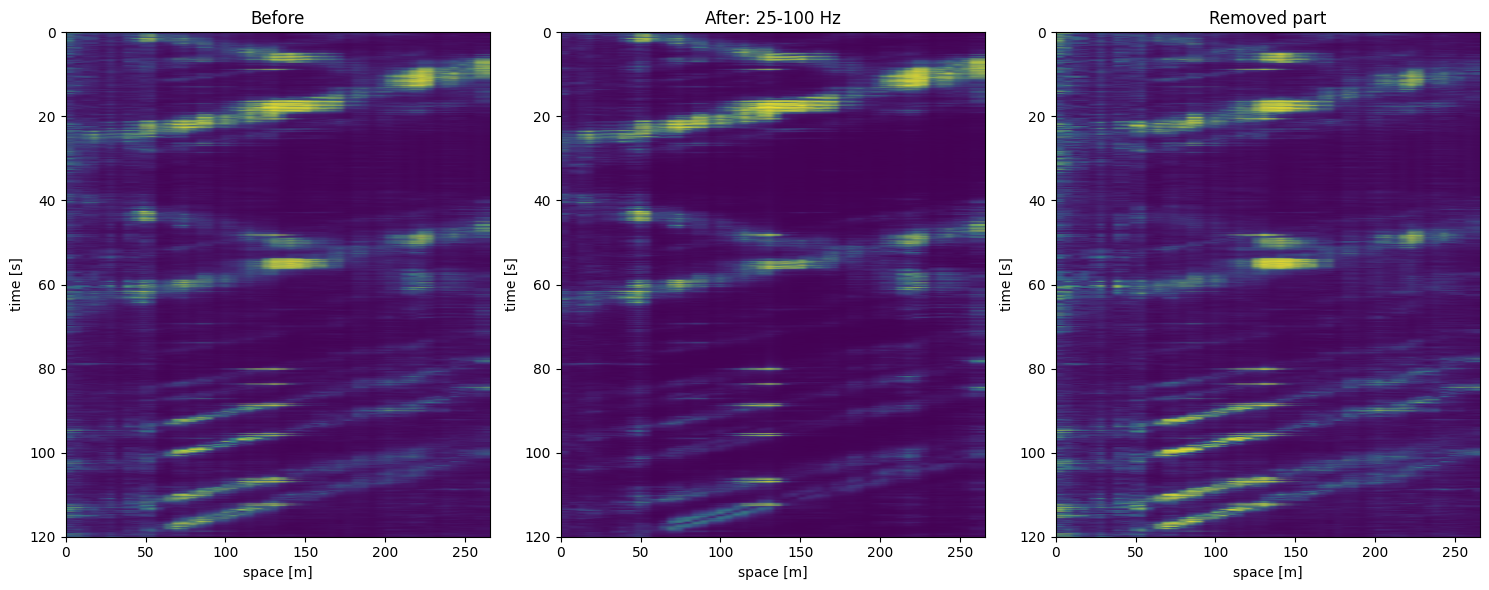

In [127]:
LOW, HIGH = 25, 100
filtered = band_filter(x, LOW, HIGH)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
show_image(axes[0], np.abs(x - x.mean(axis=0)), "Before")
show_image(axes[1], np.abs(filtered), "After: 25-100 Hz")
show_image(axes[2], np.abs(x - filtered), "Removed part")
plt.tight_layout()
plt.show()

The right image shows the part that we removed. It is noisy and the lines are weaker there. The slanted lines are clearer in the middle image.

### 6.2 Absolute Value and Downsampling

After the filter, the signal goes up and down very fast. We take the absolute value to get the strength of the vibration. Then we take the mean of every 125 samples. This is 0.2 seconds. The data gets smaller. It has 600 rows instead of 75000 rows.

The new time step is 0.2 s. We must use it when we calculate the speed.

Shape before: (75000, 52)  Shape after: (600, 52)
New time step: 0.2 s


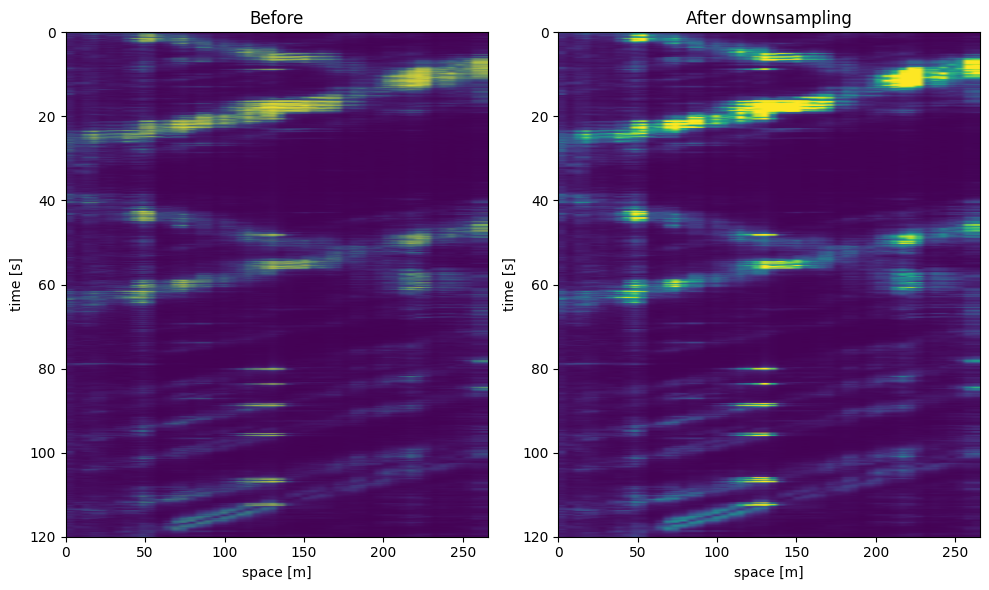

In [128]:
FACTOR = 125                  # 125 samples = 0.2 seconds
ROW_DT = FACTOR * DT          # new time step [s]

envelope = np.abs(filtered)
n_rows = envelope.shape[0] // FACTOR
small = envelope[:n_rows * FACTOR].reshape(n_rows, FACTOR, -1).mean(axis=1)
print("Shape before:", envelope.shape, " Shape after:", small.shape)
print("New time step:", ROW_DT, "s")

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
show_image(axes[0], envelope, "Before")
show_image(axes[1], small, "After downsampling")
plt.tight_layout()
plt.show()

### 6.3 Normalization

Some channels are louder than others. We divide each channel by its median. Now all channels have a similar level.

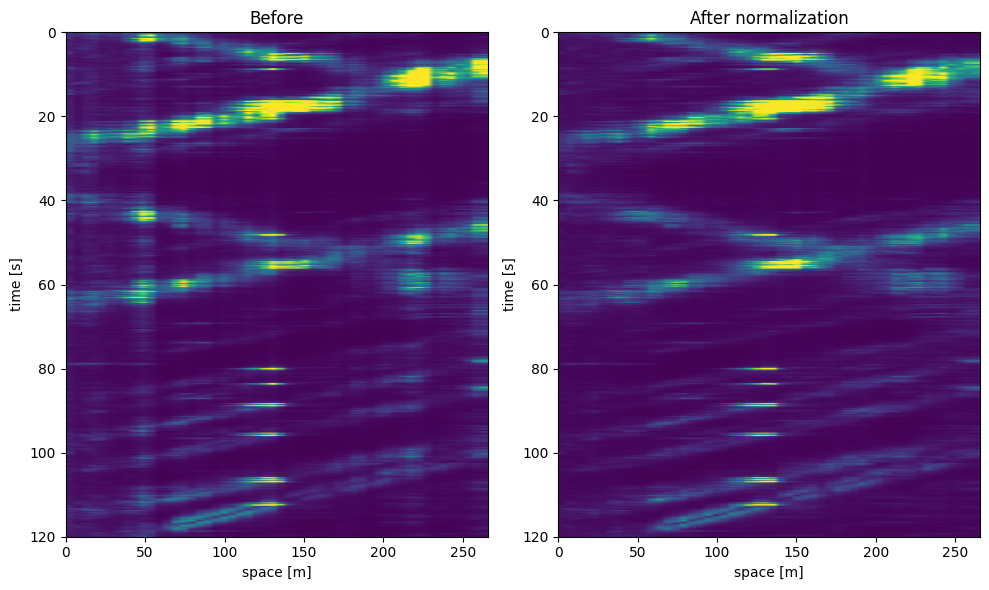

In [129]:
normalized = small / np.median(small, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
show_image(axes[0], small, "Before")
show_image(axes[1], normalized, "After normalization")
plt.tight_layout()
plt.show()

The bright vertical stripes are weaker now.

### 6.4 Common Noise

Some noise appears in all channels at the same time. It makes horizontal lines. At each time, we subtract the median of all channels. Negative values are set to zero.

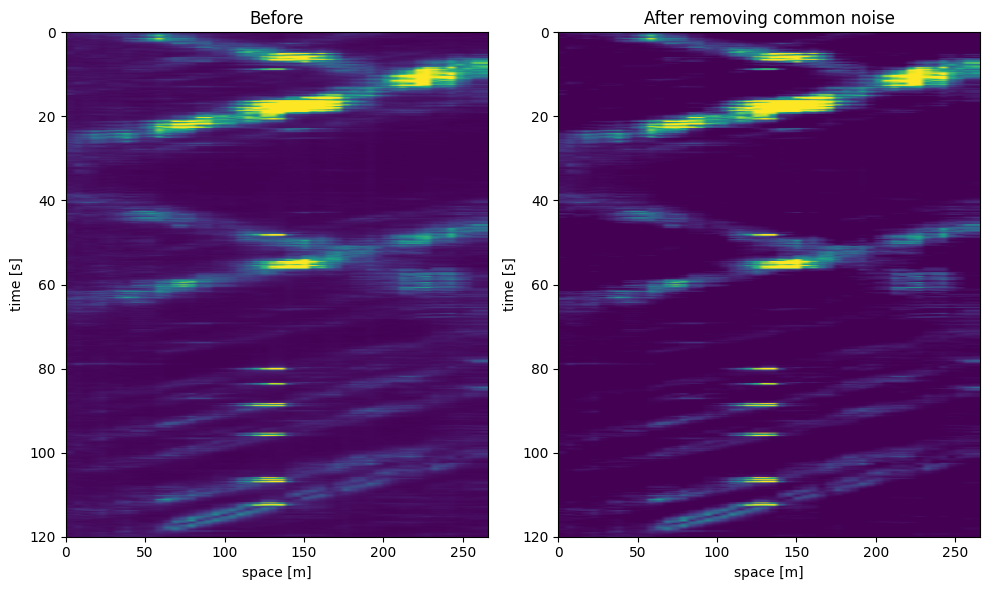

In [130]:
common = np.median(normalized, axis=1, keepdims=True)
clean = np.clip(normalized - common, 0, None)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
show_image(axes[0], normalized, "Before")
show_image(axes[1], clean, "After removing common noise")
plt.tight_layout()
plt.show()

The horizontal noise is smaller now.

### 6.5 Smoothing and Log

We smooth the image a little with a Gaussian filter. We make the image 4 times wider, so the lines are not too steep. We also take the log of 1 plus the value. A few values are very big and the log makes them smaller.

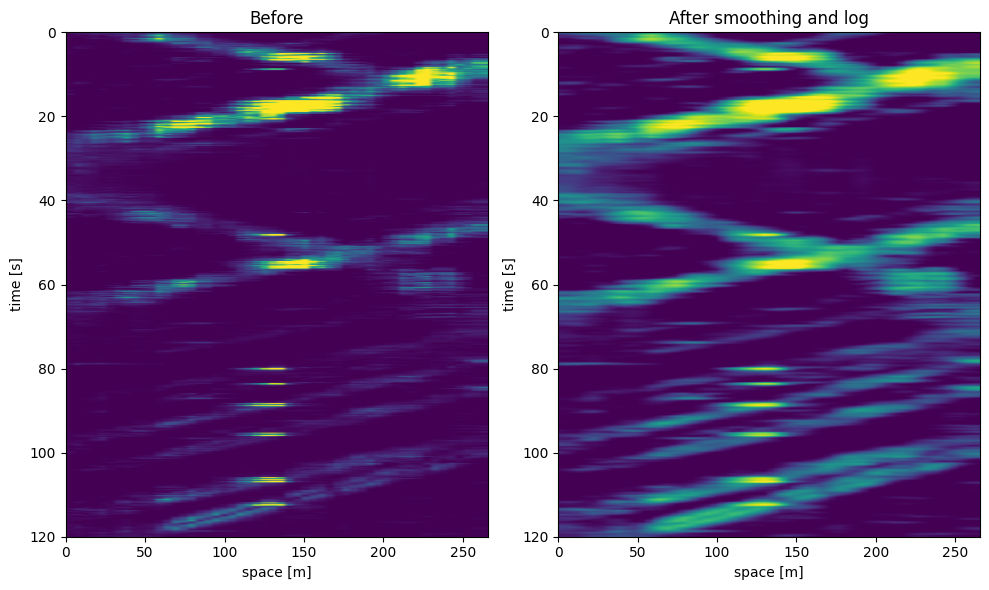

In [131]:
WIDE = 4                      # the image gets 4 times wider

smooth = cv2.GaussianBlur(clean.astype(np.float32), (3, 3), 0)
wide = cv2.resize(smooth, (smooth.shape[1] * WIDE, smooth.shape[0]))
final = np.log1p(wide)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
show_image(axes[0], clean, "Before")
show_image(axes[1], final, "After smoothing and log")
plt.tight_layout()
plt.show()

### 6.6 All Steps in One Function

Now we put all the steps in one function. We use it for the three segments.

In [132]:
def preprocess(x):
    y = np.abs(band_filter(x, LOW, HIGH))
    n_rows = y.shape[0] // FACTOR
    y = y[:n_rows * FACTOR].reshape(n_rows, FACTOR, -1).mean(axis=1)
    y = y / np.median(y, axis=0)
    y = np.clip(y - np.median(y, axis=1, keepdims=True), 0, None)
    y = cv2.GaussianBlur(y.astype(np.float32), (3, 3), 0)
    y = cv2.resize(y, (y.shape[1] * WIDE, y.shape[0]))
    return np.log1p(y)

images = {}
for label, x in data.items():
    images[label] = preprocess(x)
    print(label, images[label].shape)

A (600, 208)
B (600, 208)
C (600, 208)


The three images are ready. The slanted lines are clear in all of them.

## 7. Keeping Only the Slanted Lines

### 7.1 Threshold

We make a binary mask. For this we need a threshold. We do not choose it by hand. The Otsu method finds it automatically for each segment.

A: threshold = 0.85
B: threshold = 0.88
C: threshold = 1.02


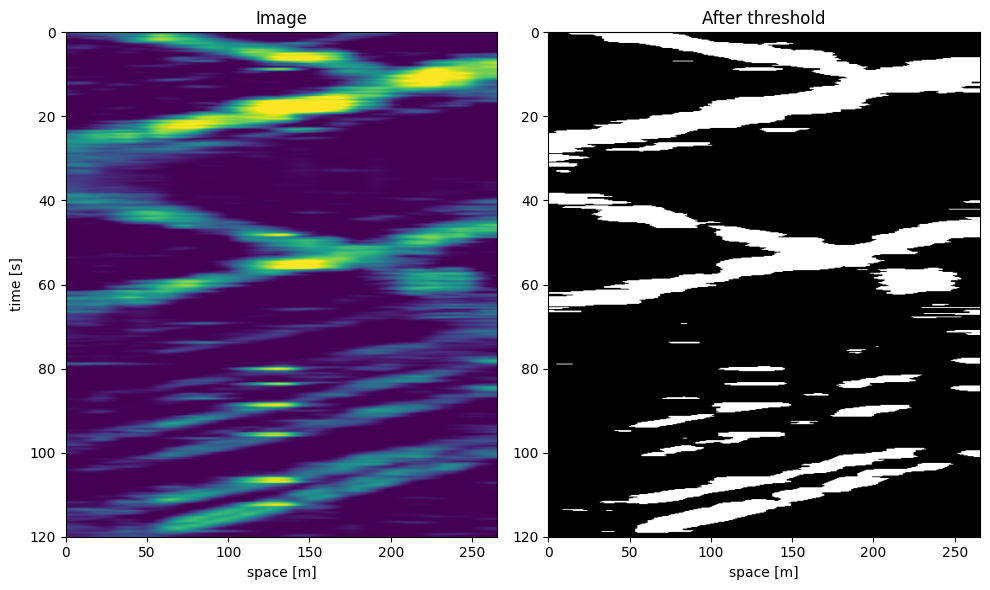

In [133]:
masks = {}
for label, img in images.items():
    t = threshold_otsu(img)
    masks[label] = img > t
    print(f"{label}: threshold = {t:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
show_image(axes[0], images["C"], "Image")
axes[1].imshow(masks["C"], aspect="auto", cmap="gray", extent=[0, n_channels * DX, 120, 0])
axes[1].set_title("After threshold")
axes[1].set_xlabel("space [m]")
plt.tight_layout()
plt.show()

The strong lines are white in the mask. There are also many small white parts. They are noise.

### 7.2 Removing Small Parts

We remove the white parts that are smaller than 150 pixels. They are not vehicles.

C:\Users\Asus\AppData\Local\Temp\ipykernel_40872\3854256710.py:3: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  masks[label] = remove_small_objects(masks[label], 150)


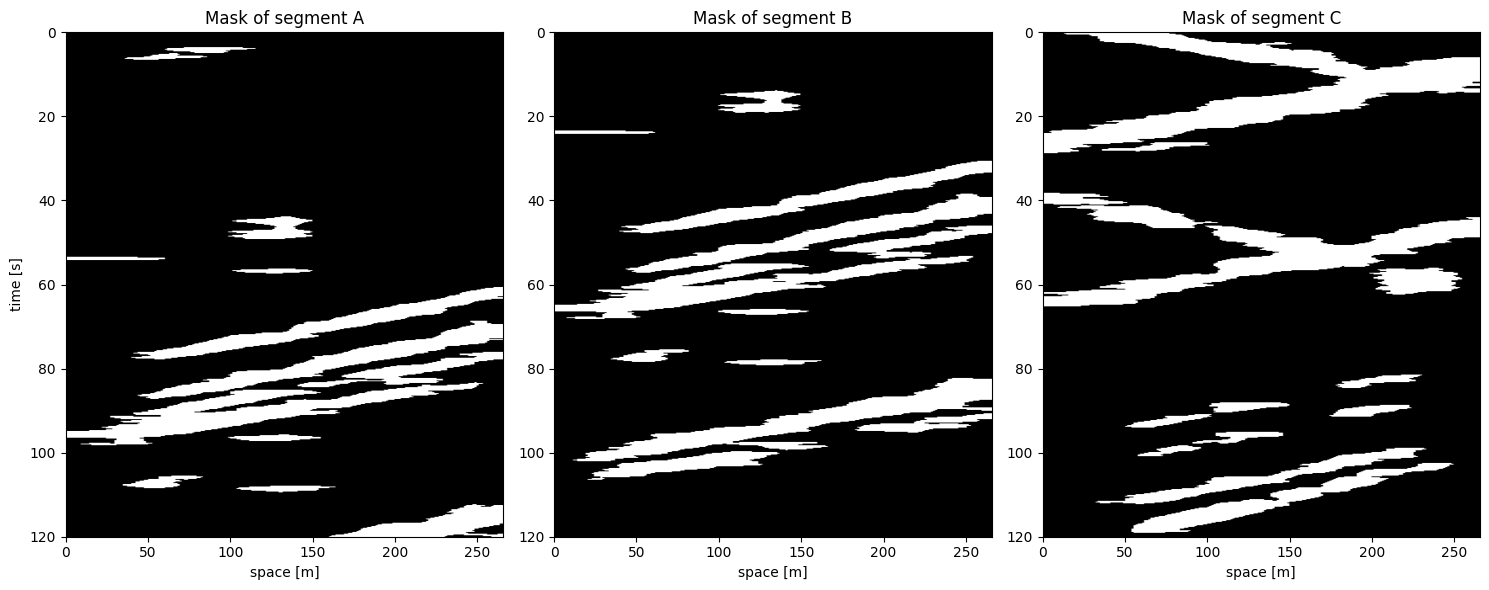

White pixels in C before: 24052  after: 22711


In [134]:
before = masks["C"]
for label in masks:
    masks[label] = remove_small_objects(masks[label], 150)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
for ax, label in zip(axes, masks):
    ax.imshow(masks[label], aspect="auto", cmap="gray", extent=[0, n_channels * DX, 120, 0])
    ax.set_title(f"Mask of segment {label}")
    ax.set_xlabel("space [m]")
axes[0].set_ylabel("time [s]")
plt.tight_layout()
plt.show()
print("White pixels in C before:", before.sum(), " after:", masks["C"].sum())

The masks show the strong slanted lines. A few short horizontal parts are still there. They are not a problem, because the next step looks only for slanted lines.

## 8. Line Detection and Speed

### 8.1 Hough Transform and Grouping

The Hough transform finds straight pieces in the mask. One vehicle gives many pieces. We ignore pieces with a speed that is not possible, below 5 km/h or above 150 km/h.

Pieces with a similar slope that are close to each other belong to the same vehicle. We put them in one group and fit one line for each group.

First we write the functions. We also use them in Section 9.

In [135]:
def speed_of(a):
    """Speed in km/h from the slope a = pixels of space per row of time."""
    return a / WIDE * DX / ROW_DT * 3.6


def hough_pieces(mask, min_len=50, gap=10, thr=40):
    """Find small straight pieces in the mask with the Hough transform."""
    found = cv2.HoughLinesP(mask.astype(np.uint8) * 255, 1, np.pi / 180, thr,
                            minLineLength=min_len, maxLineGap=gap)
    pieces = []
    if found is None:
        return pieces
    for x1, y1, x2, y2 in found.reshape(-1, 4):
        if y1 == y2:
            continue
        a = (x2 - x1) / (y2 - y1)
        if 5 < abs(speed_of(a)) < 150:
            pieces.append((x1, y1, x2, y2))
    return pieces


def group_pieces(pieces, dist=22):
    """Put pieces with a similar slope that are close to each other in one group."""
    pieces = sorted(pieces, key=lambda p: -((p[2] - p[0]) ** 2 + (p[3] - p[1]) ** 2))
    groups = []
    for x1, y1, x2, y2 in pieces:
        a = (x2 - x1) / (y2 - y1)
        y_mid = (y1 + y2) / 2
        x_mid = (x1 + x2) / 2
        for g in groups:
            same_slope = abs(a - g["a"]) <= 0.3 * max(abs(g["a"]), 0.2)
            close = abs(g["a"] * y_mid + g["b"] - x_mid) < dist
            if same_slope and close:
                g["points"] += [(y1, x1), (y2, x2)]
                p = np.array(g["points"])
                g["a"], g["b"] = np.polyfit(p[:, 0], p[:, 1], 1)
                break
        else:
            groups.append({"a": a, "b": x1 - a * y1, "points": [(y1, x1), (y2, x2)]})
    return [(g["a"], g["b"]) for g in groups]


def refine_line(img, mask, a, b, width=8):
    """Fit the line again with the mask pixels near it. We repeat this 3 times."""
    ys, xs = np.nonzero(mask)
    weight = img[ys, xs]
    for i in range(3):
        near = np.abs(xs - (a * ys + b)) < width
        if near.sum() < 100:
            return None
        a, b = np.polyfit(ys[near], xs[near], 1, w=weight[near])
    near = np.abs(xs - (a * ys + b)) < width
    return a, b, ys[near], xs[near]


def too_close(line1, line2):
    """Two lines in the same direction that are close are the same vehicle."""
    start = max(line1[2], line2[2])
    end = min(line1[3], line2[3])
    if end - start < 30 or line1[0] * line2[0] < 0:
        return False
    ys = np.arange(start, end)
    diff = np.abs((line1[0] * ys + line1[1]) - (line2[0] * ys + line2[1]))
    return diff.mean() < 16


def find_lines(img, mask, old_lines=(), min_span=50, min_cover=0.65,
               min_pixels=100, max_speed=120, hough=(50, 10, 40)):
    """Find the lines in a mask. Returns a list of (a, b, y_start, y_end)."""
    candidates = []
    for a, b in group_pieces(hough_pieces(mask, *hough)):
        result = refine_line(img, mask, a, b)
        if result is not None:
            candidates.append(result)
    candidates.sort(key=lambda r: -len(r[2]))      # biggest first

    lines = list(old_lines)
    used = np.zeros(mask.shape, bool)
    for a, b, ys, xs in candidates:
        if used[ys, xs].mean() > 0.5 or len(ys) < min_pixels:
            continue
        y0, y1 = ys.min(), ys.max()
        cover = len(np.unique(ys)) / (y1 - y0 + 1)
        long_enough = abs(a * (y1 - y0)) >= min_span
        speed_ok = 30 < abs(speed_of(a)) < max_speed
        if cover < min_cover or not long_enough or not speed_ok:
            continue
        used[ys, xs] = True
        if any(too_close((a, b, y0, y1), line) for line in lines):
            continue
        lines.append((a, b, y0, y1))
    return lines[len(old_lines):]


def draw_lines(ax, lines, color):
    for a, b, y0, y1 in lines:
        space = np.array([a * y0 + b, a * y1 + b]) / WIDE * DX
        time = np.array([y0, y1]) * ROW_DT
        ax.plot(space, time, color, linewidth=2)
        ax.text(space.mean(), time.mean(), f"{speed_of(a):.0f}", color="yellow")
    ax.set_xlim(0, n_channels * DX)
    ax.set_ylim(120, 0)

Now we try the functions on segment C.

Number of pieces: 139
Number of groups: 14


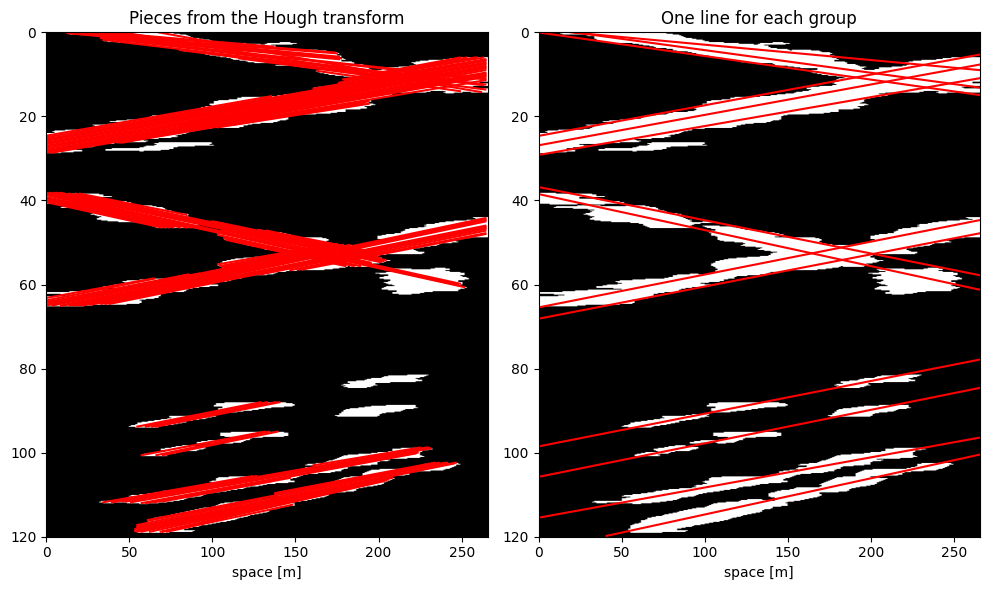

In [136]:
pieces = hough_pieces(masks["C"])
print("Number of pieces:", len(pieces))

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
for ax in axes:
    ax.imshow(masks["C"], aspect="auto", cmap="gray", extent=[0, n_channels * DX, 120, 0])
    ax.set_xlabel("space [m]")
for x1, y1, x2, y2 in pieces:
    axes[0].plot([x1 / WIDE * DX, x2 / WIDE * DX], [y1 * ROW_DT, y2 * ROW_DT], "r")
axes[0].set_title("Pieces from the Hough transform")

groups = group_pieces(pieces)
print("Number of groups:", len(groups))
for a, b in groups:
    space = np.array([a * 0 + b, a * 599 + b]) / WIDE * DX
    axes[1].plot(space, [0, 599 * ROW_DT], "r")
axes[1].set_xlim(0, n_channels * DX)
axes[1].set_ylim(120, 0)
axes[1].set_title("One line for each group")
plt.tight_layout()
plt.show()

The left image shows many pieces. The right image shows one line for each group. Some groups are not real vehicles, so we check them in the next step.

### 8.2 Checking the Lines

The lines from the groups are not exact, because the bands are thick. For each line, we take the mask pixels near the line and fit the line again. We do this 3 times.

Then we remove the bad lines:
- the line is too short
- the line has holes, so the band is not continuous
- the speed is below 30 km/h or above 120 km/h
- the line is almost the same as another line

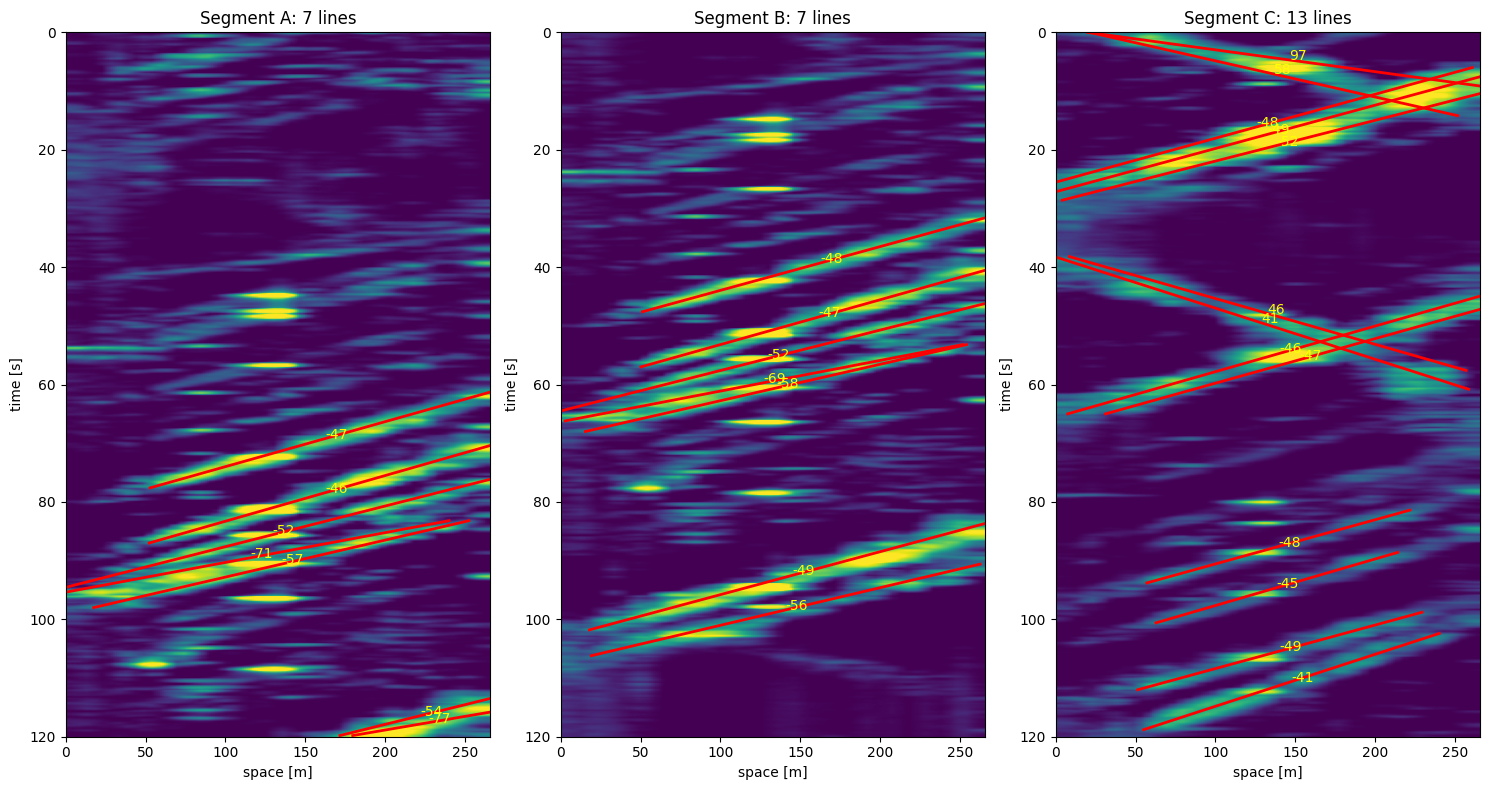

In [137]:
thick_lines = {}
for label in images:
    thick_lines[label] = find_lines(images[label], masks[label])

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for ax, label in zip(axes, images):
    show_image(ax, images[label], f"Segment {label}: {len(thick_lines[label])} lines")
    draw_lines(ax, thick_lines[label], "r")
plt.tight_layout()
plt.show()

The red lines are the vehicles that we found. The number on each line is the speed in km/h.

### 8.3 Speed and Direction

The slope of a line gives the speed. One row is 0.2 s and one pixel is a quarter of a channel. So:

speed = pixels / 4 x DX / 0.2 x 3.6 km/h

The sign of the slope gives the direction. Direction 1 means that the vehicle goes to higher positions on the cable. Direction -1 means lower positions.

In [138]:
def print_lines(label, lines):
    print(f"Segment {label}: {len(lines)} lines")
    print("  start     end       direction  speed [km/h]")
    for a, b, y0, y1 in sorted(lines, key=lambda l: l[2]):
        start = (start_time[label] + datetime.timedelta(seconds=y0 * ROW_DT)).strftime("%H:%M:%S")
        end = (start_time[label] + datetime.timedelta(seconds=y1 * ROW_DT)).strftime("%H:%M:%S")
        direction = 1 if a > 0 else -1
        print(f"  {start}  {end}  {direction:6d}     {abs(speed_of(a)):8.1f}")

for label in thick_lines:
    print_lines(label, thick_lines[label])

Segment A: 7 lines
  start     end       direction  speed [km/h]
  09:38:52  09:39:09      -1         47.0
  09:39:01  09:39:19      -1         46.2
  09:39:08  09:39:27      -1         51.9
  09:39:15  09:39:30      -1         57.1
  09:39:15  09:39:27      -1         70.9
  09:39:45  09:39:51      -1         53.6
  09:39:47  09:39:51      -1         77.5
Segment B: 7 lines
  start     end       direction  speed [km/h]
  09:38:53  09:39:09      -1         48.2
  09:39:02  09:39:19      -1         47.1
  09:39:08  09:39:27      -1         52.2
  09:39:15  09:39:30      -1         58.0
  09:39:15  09:39:28      -1         68.9
  09:39:45  09:40:03      -1         49.2
  09:39:52  09:40:08      -1         56.1
Segment C: 13 lines
  start     end       direction  speed [km/h]
  09:12:02  09:12:16       1         58.4
  09:12:02  09:12:11       1         96.7
  09:12:08  09:12:28      -1         48.1
  09:12:09  09:12:29      -1         48.8
  09:12:12  09:12:30      -1         51.8
  09:1

Most speeds are between 40 and 60 km/h. In segments A and B, all vehicles go in direction -1. Segment C has vehicles in both directions.

We have no ground truth for the real data, so we checked the lines by eye. Vehicles that are very close to each other can be joined in one band, so we may miss some of them.

## 9. Faint Lines

Thin lines are cars. They are fainter than trams and trucks, so the Otsu threshold misses them. We use a second path:

1. Remove the strong lines from the image.
2. Find a new threshold with Otsu on the rest of the image.
3. Find the lines again with the same functions. Here we ask for more pixels and fewer holes, so we get fewer false lines.

C:\Users\Asus\AppData\Local\Temp\ipykernel_40872\1839398224.py:13: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask2 = remove_small_objects(rest > threshold_otsu(rest), 60)


Segment A: 7 strong lines and 2 faint lines
Segment B: 7 strong lines and 5 faint lines
Segment C: 13 strong lines and 2 faint lines


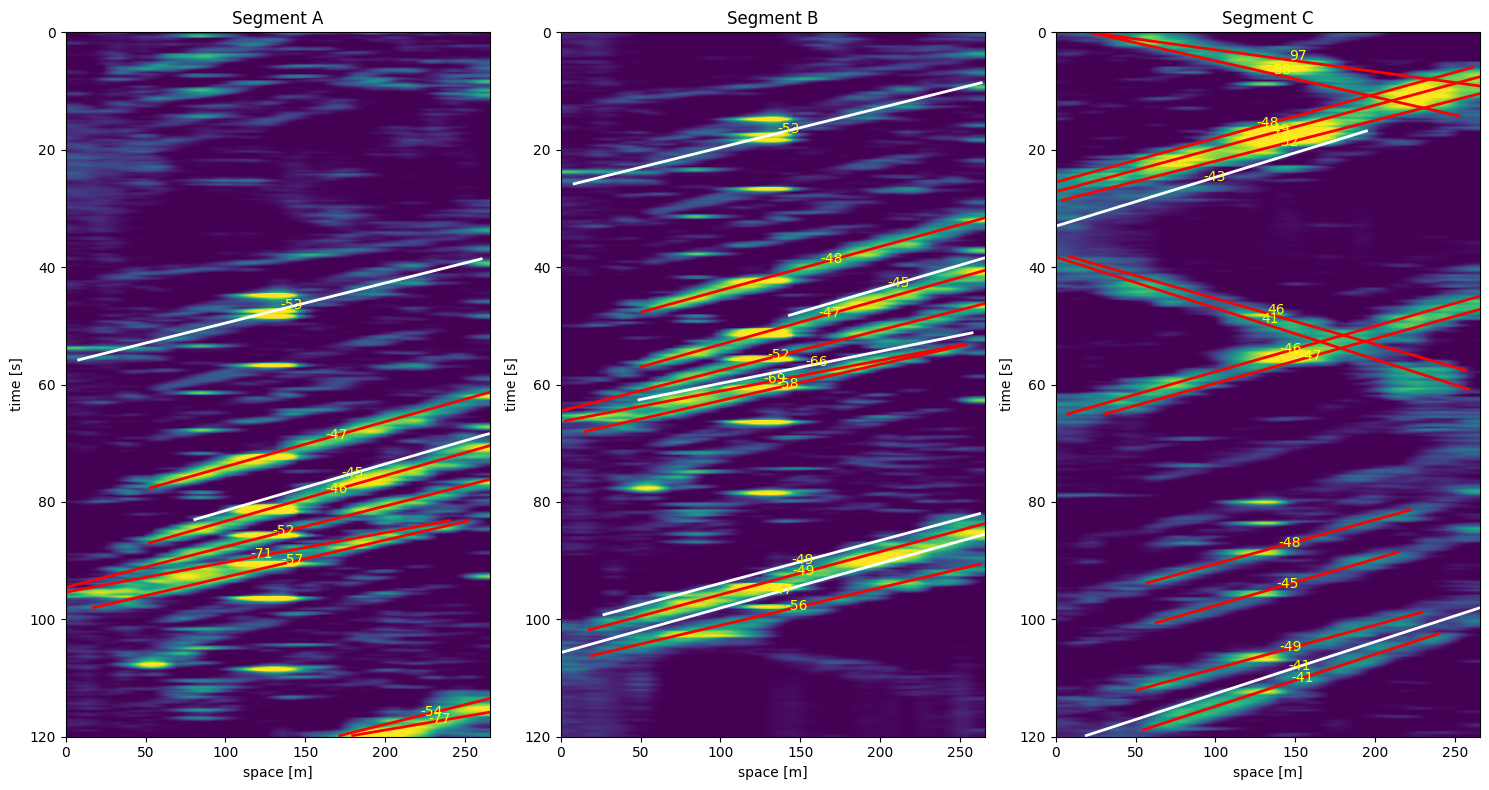

In [139]:
def remove_lines(img, lines, half=16):
    """Set the image to 0 around the lines that we already found."""
    rest = img.copy()
    rows, cols = np.mgrid[0:img.shape[0], 0:img.shape[1]]
    for a, b, y0, y1 in lines:
        near = (np.abs(cols - (a * rows + b)) < half) & (rows >= y0 - 5) & (rows <= y1 + 5)
        rest[near] = 0
    return rest

thin_lines = {}
for label in images:
    rest = remove_lines(images[label], thick_lines[label])
    mask2 = remove_small_objects(rest > threshold_otsu(rest), 60)
    thin_lines[label] = find_lines(rest, mask2, old_lines=thick_lines[label], min_span=40,
                                   min_cover=0.8, min_pixels=400, max_speed=100,
                                   hough=(35, 12, 25))

fig, axes = plt.subplots(1, 3, figsize=(15, 8))
for ax, label in zip(axes, images):
    show_image(ax, images[label], f"Segment {label}")
    draw_lines(ax, thick_lines[label], "r")
    draw_lines(ax, thin_lines[label], "w")
    print(f"Segment {label}: {len(thick_lines[label])} strong lines and {len(thin_lines[label])} faint lines")
plt.tight_layout()
plt.show()

White lines are the faint lines and red lines are the strong lines.

### 9.1 All Lines

The table shows all lines in each segment.

In [140]:
for label in images:
    print_lines(label, thick_lines[label] + thin_lines[label])

Segment A: 9 lines
  start     end       direction  speed [km/h]
  09:38:30  09:38:47      -1         52.7
  09:38:52  09:39:09      -1         47.0
  09:39:00  09:39:15      -1         45.3
  09:39:01  09:39:19      -1         46.2
  09:39:08  09:39:27      -1         51.9
  09:39:15  09:39:30      -1         57.1
  09:39:15  09:39:27      -1         70.9
  09:39:45  09:39:51      -1         53.6
  09:39:47  09:39:51      -1         77.5
Segment B: 12 lines
  start     end       direction  speed [km/h]
  09:38:30  09:38:47      -1         53.3
  09:38:53  09:39:09      -1         48.2
  09:39:00  09:39:10      -1         45.0
  09:39:02  09:39:19      -1         47.1
  09:39:08  09:39:27      -1         52.2
  09:39:13  09:39:24      -1         65.8
  09:39:15  09:39:30      -1         58.0
  09:39:15  09:39:28      -1         68.9
  09:39:44  09:40:01      -1         49.2
  09:39:45  09:40:03      -1         49.2
  09:39:47  09:40:08      -1         47.3
  09:39:52  09:40:08      -1 

We find more vehicles with the second path. We cannot measure the accuracy, because we have no ground truth. Some faint lines can be false, and some cars are missed.